# Дослідження даних (EDA)
Використовувати можна статистику **тільки на train**.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent 
DATA = ROOT / "data" / "processed"

baskets = pd.read_parquet(DATA / "baskets.parquet")
products = pd.read_parquet(DATA / "products.parquet")
train = baskets[baskets["split"] == "train"]
test = baskets[baskets["split"] == "test"]

## 1. Розмір кошиків

In [20]:
basket_size = baskets.groupby("order_id").size()
display(basket_size.describe().round(1))

count    100000.0
mean         10.1
std           7.5
min           1.0
25%           5.0
50%           8.0
75%          14.0
max          92.0
dtype: float64

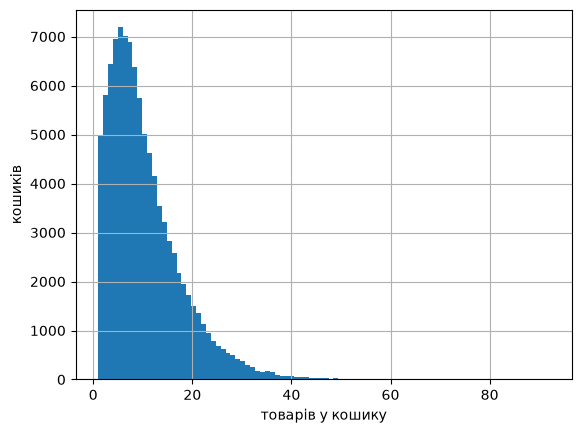

In [22]:
basket_size.hist(bins=max(basket_size))
plt.xlabel("товарів у кошику")
plt.ylabel("кошиків")
plt.show()

In [23]:
print(f"кошиків з 1 товаром: {(basket_size == 1).mean():.1%}")

кошиків з 1 товаром: 5.0%


## 2. Популярність товарів і довгий хвіст

In [24]:
popularity = train.groupby("product_id")["order_id"].nunique().sort_values(ascending=False)
n_orders = train["order_id"].nunique()

top10 = popularity.head(10).rename("orders").to_frame()
top10["share_of_orders"] = (top10["orders"] / n_orders).round(3)
display(top10.join(products.set_index("product_id")[["product_name", "department"]]))

,orders,share_of_orders,product_name,department
product_id,,,,
24852,10596,0.147,Banana,produce
13176,8413,0.117,Bag of Organic Bananas,produce
21137,5890,0.082,Organic Strawberries,produce
21903,5357,0.074,Organic Baby Spinach,produce
47209,4800,0.067,Organic Hass Avocado,produce
47766,3861,0.054,Organic Avocado,produce
47626,3492,0.048,Large Lemon,produce
16797,3199,0.044,Strawberries,produce
26209,3161,0.044,Limes,produce


In [25]:
for n in [1, 2, 5, 10]:
    print(f"товарів, що трапились <= {n:>2} разів: {(popularity <= n).mean():.0%}")

товарів, що трапились <=  1 разів: 26%
товарів, що трапились <=  2 разів: 40%
товарів, що трапились <=  5 разів: 60%
товарів, що трапились <= 10 разів: 73%


In [27]:
cumulative_share = popularity.cumsum() / popularity.sum()
for top in [100, 1000, 5000]:
    print(f"топ-{top} товарів = {cumulative_share.iloc[top - 1]:.0%} з усіх куплених товарів")

топ-100 товарів = 23% з усіх куплених товарів
топ-1000 товарів = 54% з усіх куплених товарів
топ-5000 товарів = 82% з усіх куплених товарів


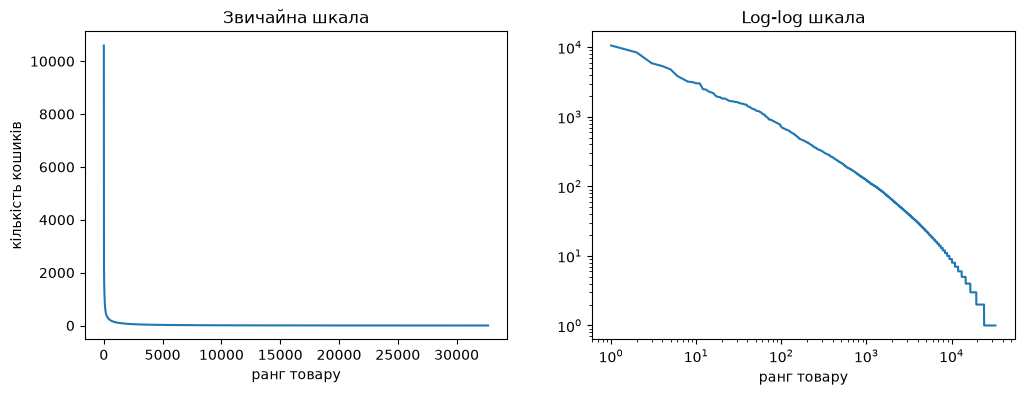

In [28]:
rank = range(1, len(popularity) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(rank, popularity.values)
ax1.set_title("Звичайна шкала")
ax1.set_xlabel("ранг товару")
ax1.set_ylabel("кількість кошиків")

ax2.loglog(rank, popularity.values)
ax2.set_title("Log-log шкала")
ax2.set_xlabel("ранг товару")

plt.show()

## 3. Дублікати і пропуски

In [7]:
print("пропусків:", baskets.isna().sum().sum())
print("дублікатів (order_id, product_id):", baskets.duplicated(["order_id", "product_id"]).sum())
print(f"частка повторних покупок (reordered=1): {baskets['reordered'].mean():.0%}")

пропусків: 0
дублікатів (order_id, product_id): 0
частка повторних покупок (reordered=1): 59%


## 4. Вагомі товари
Рахуємо товари, що були щонайменше `min_count` разів.
Та визначаємо скільки теоретично можуть максимум покрити відсотків на тесті.

In [29]:
t = test.sort_values(["order_id", "add_to_cart_order"]).copy()
t["pos"] = t.groupby("order_id").cumcount()
t["size"] = t.groupby("order_id")["product_id"].transform("size")
hidden = t[(t["size"] >= 2) & (t["pos"] >= t["size"] // 2)]

rows = []
for min_count in [1, 2, 3, 5, 10, 20]:
    valuable_products = popularity[popularity >= min_count].index
    rows.append({"min_count": min_count, "number_of_products": len(valuable_products),
                 "coverage": hidden["product_id"].isin(valuable_products).mean().round(3)})
display(pd.DataFrame(rows))

,min_count,number_of_products,coverage
0,1,32680,0.986
1,2,24020,0.971
2,3,19450,0.958
3,5,14603,0.934
4,10,9414,0.886
5,20,5645,0.812


## Висновки
1. **Кошики:** медіана 8 товарів, середнє 10, максимум 92. Лише 5% кошиків з 1 товаром (не оцінюємо бо нічого ховати).
2. **Популярність домінує:** банани є в 15% кошиків, органічні банани в 12%. Увесь топ-10 це фрукти/овочі і молоко. 59% покупок повторно. 
3. **Дані чисті:** пропусків і дублікатів немає.
4. **Довгий хвіст:** 26% товарів трапились у train лише 1 раз, 60% товаріа не більше 5 разів. Для них статистика спільних покупок ненадійна, для цього розглянуто потрібна мінімальна межа для врахування товару.
5. **Вагомі товари:** беремо товари з **min_count = 5** у train, це забезпечить доволі велике покриття прихованих товарів 93%, а також багато товарів з малою інформацією видаляються. Також менша кількість товарів дозволить виконувати обрахунки швидше та менше памяті використовувати - якщо б це стало проблемою в подальшому. 